# 06 — Chọn ngưỡng cho stay-point, home và office

NB05 mới khảo sát stay-point sơ bộ (số stay theo D, T). Notebook này đi tiếp, đo các câu hỏi cần trả lời trước khi định nghĩa home/office:
1. **D và T:** D nhỏ có chẻ một lần dừng thành nhiều mảnh không? T bao nhiêu thì hết nhận nhầm lúc đang đi xe là dừng?
2. **max_gap:** khoảng không ghi dài bao nhiêu thì vẫn coi là user ở yên một chỗ?
3. **Khung đêm / khung hành chính:** stay qua đêm và stay ban ngày thực tế bắt đầu, kết thúc lúc mấy giờ?
4. **Lượng dữ liệu tối thiểu:** cần bao nhiêu đêm / ngày làm việc có dữ liệu thì tìm được home / office? Home có đổi theo thời gian không?
5. **Office:** bao nhiêu user không có nơi làm việc tách khỏi nhà? Office ứng viên ít ngày có phải là chuyến đi không?

Dữ liệu chuẩn bị giống NB05: đọc raw, bỏ toạ độ/năm lỗi và điểm trùng timestamp, giờ local theo timezone chính xác (NB02),
ngày làm việc theo lịch chính thức (NB03).

Nhãn phương tiện (`labels.txt` của 69 user) không phải ground truth cho home/office. Ở đây nhãn chỉ dùng làm **kiểm tra chéo**:
một stay mà phần lớn điểm có nhãn `car` thì là stay giả.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numba import njit
from sklearn.cluster import DBSCAN

from utils import add_calendar, add_geo, china_calendar, haversine, load_points, savefig, setup_style

setup_style()
MOTOR = ["bus", "car", "taxi", "subway", "train", "airplane", "motorcycle", "boat"]

pts = load_points(["user", "traj_id", "lat", "lon", "ts_utc", "mode"])
pts = pts[pts.lat.between(-90, 90) & (pts.ts_utc.dt.year >= 2007)]
pts = pts.sort_values(["user", "ts_utc"], kind="stable").drop_duplicates(["user", "ts_utc"]).reset_index(drop=True)
pts = add_calendar(add_geo(pts))
ts = pts.ts_utc.to_numpy().astype("datetime64[s]").astype(np.int64).astype(np.float64)
off = pts.utc_offset_h.to_numpy() * 3600
lat, lon = pts.lat.to_numpy(), pts.lon.to_numpy()
mode = pts["mode"].astype(str).to_numpy()
labeled = pts["mode"].notna().to_numpy()
motor = labeled & np.isin(mode, MOTOR)
same_user = np.r_[False, pts.user.to_numpy()[1:] == pts.user.to_numpy()[:-1]]
dtu = np.where(same_user, np.r_[0, np.diff(ts)], 0)
idx_user = pts.groupby("user").indices
print(f"{len(pts):,} điểm, {len(idx_user)} user")

24,178,074 điểm, 182 user


## Chuẩn bị: thuật toán stay-point, place, giờ đêm / giờ hành chính

- **Stay-point** (Li et al., 2008): đoạn điểm liên tiếp nằm trong bán kính D quanh điểm đầu, kéo dài ≥ T. Chạy trên **toàn chuỗi
  điểm của user** để khoảng không ghi giữa hai file cũng thành stay (NB01 mục 6, NB05 mục 3). Bỏ stay có khoảng không ghi bên trong > max_gap.
- **Place:** gom stay của cùng user bằng DBSCAN (haversine, eps = 200 m, min_samples = 1).
- **Giờ đêm** = phần thời gian stay nằm trong 22–06 local; **giờ hành chính** = phần nằm trong 09–18 của ngày làm việc.

In [2]:
@njit
def _hav(a1, o1, a2, o2):
    r = np.pi / 180
    x = np.sin((a2 - a1) * r / 2) ** 2 + np.cos(a1 * r) * np.cos(a2 * r) * np.sin((o2 - o1) * r / 2) ** 2
    return 2 * 6371008.8 * np.arcsin(np.sqrt(x))


@njit
def stay_points(lat, lon, t, D, T):
    n = len(lat); out = []; i = 0
    while i < n:
        j = i + 1
        while j < n and _hav(lat[i], lon[i], lat[j], lon[j]) <= D:
            j += 1
        if t[j - 1] - t[i] >= T:
            out.append((i, j - 1)); i = j
        else:
            i += 1
    return out


def detect(D, T, max_gap_h=None):
    """Mảng (i0, i1) chỉ số điểm đầu/cuối của từng stay, theo thứ tự (user, thời gian)."""
    rows = [(idx[i], idx[j]) for idx in idx_user.values() for i, j in stay_points(lat[idx], lon[idx], ts[idx], D, T)]
    s = np.array(rows)
    if max_gap_h is not None:
        mg = np.array([dtu[a + 1:b + 1].max() if b > a else 0 for a, b in s]) / 3600
        s = s[mg <= max_gap_h]
    return s


def stay_table(s):
    a, b = s[:, 0], s[:, 1]
    cs_a, cs_o = np.r_[0, np.cumsum(lat)], np.r_[0, np.cumsum(lon)]
    n = b - a + 1
    st = pd.DataFrame({"user": pts.user.to_numpy()[a],
                       "start": pd.to_datetime(ts[a] + off[a], unit="s"), "end": pd.to_datetime(ts[b] + off[a], unit="s"),
                       "in_china": pts.in_china.to_numpy()[a],
                       "lat": (cs_a[b + 1] - cs_a[a]) / n, "lon": (cs_o[b + 1] - cs_o[a]) / n})
    st["dur_h"] = (st.end - st.start).dt.total_seconds() / 3600
    lab = np.full(len(st), -1)
    for idx in st.groupby("user").indices.values():
        X = np.radians(st.iloc[idx][["lat", "lon"]].to_numpy())
        lab[idx] = DBSCAN(eps=200 / 6371008.8, min_samples=1, metric="haversine").fit_predict(X)
    st["place"] = lab
    return st


CAL_WORK = china_calendar().set_index("date").is_workday


def window_hours(st):
    """Tách mỗi stay thành từng giờ local; đánh dấu giờ đêm (22–06) và giờ hành chính (09–18, ngày làm việc)."""
    rec = []
    for r in st.itertuples():
        for h in pd.date_range(r.start.floor("h"), r.end, freq="h"):
            ov = (min(h + pd.Timedelta(hours=1), r.end) - max(h, r.start)).total_seconds() / 3600
            if ov > 0:
                rec.append((r.Index, r.user, r.place, r.in_china, h, ov))
    x = pd.DataFrame(rec, columns=["sid", "user", "place", "in_china", "h", "hrs"])
    hr = x.h.dt.hour
    cn = CAL_WORK.reindex(x.h.dt.normalize()).to_numpy()
    workday = np.where(x.in_china & ~pd.isna(cn), cn, x.h.dt.day_of_week < 5).astype(bool)
    x["night"] = (hr >= 22) | (hr < 6)
    x["work"] = workday & hr.between(9, 17)
    x["night_date"] = (x.h - pd.Timedelta(hours=6)).dt.normalize()
    x["date"] = x.h.dt.normalize()
    return x


def place_summary(st, wh):
    """Theo (user, place): giờ đêm, số đêm khác nhau, giờ hành chính, số ngày làm việc khác nhau, toạ độ."""
    n = wh[wh.night].groupby(["user", "place"]).agg(night_h=("hrs", "sum"), nights=("night_date", "nunique"))
    w = wh[wh.work].groupby(["user", "place"]).agg(work_h=("hrs", "sum"), workdays=("date", "nunique"))
    xy = st.groupby(["user", "place"])[["lat", "lon"]].mean()
    return xy.join(n).join(w).fillna(0).reset_index()

## 1. Chọn D và T

### 1.1 T: tỉ lệ stay "giả" theo nhãn phương tiện

Chỉ xét stay có ≥ 50% điểm được gán nhãn. Stay là "giả" nếu ≥ 50% số điểm có nhãn là phương tiện cơ giới (đang ngồi trên xe mà bị coi là dừng).

,D_m,T_min,stays,labeled_stays,fake_share
0,100,5,48605,7400,26.9%
1,100,10,29639,4074,23.9%
2,100,15,22722,2994,21.8%
3,100,20,18979,2491,21.0%
4,100,30,14832,2009,21.2%
5,200,5,56259,9989,28.5%
6,200,10,35211,5631,25.3%
7,200,15,28148,4343,23.6%
8,200,20,24235,3673,22.6%
9,200,30,19881,3034,22.4%


D=200, T=20: 831 stay giả, trong đó 88.2% có khoảng mất tín hiệu > 10 phút bên trong


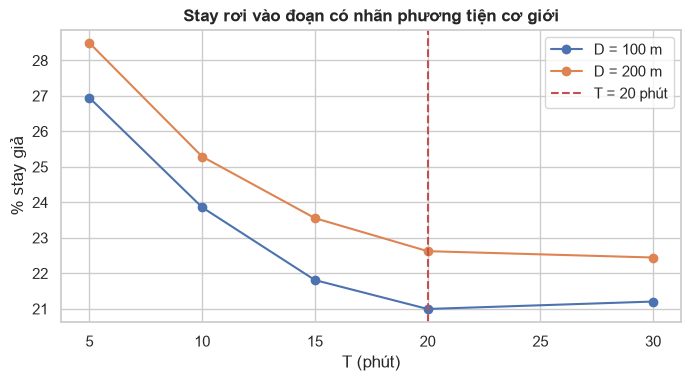

In [3]:
cs_l, cs_m = np.r_[0, np.cumsum(labeled)], np.r_[0, np.cumsum(motor)]


def fake_mask(s):
    n = s[:, 1] - s[:, 0] + 1
    ls = (cs_l[s[:, 1] + 1] - cs_l[s[:, 0]]) / n
    ms = (cs_m[s[:, 1] + 1] - cs_m[s[:, 0]]) / n
    lab = ls >= .5
    return lab, lab & (ms / np.maximum(ls, 1e-9) >= .5)


rows, S = [], {}
for D in [100, 200]:
    for T in [5, 10, 15, 20, 30]:
        S[D, T] = s = detect(D, T * 60)
        lab, fake = fake_mask(s)
        rows.append({"D_m": D, "T_min": T, "stays": len(s), "labeled_stays": lab.sum(), "fake_share": fake.sum() / lab.sum()})
st_T = pd.DataFrame(rows)
display(st_T.assign(fake_share=st_T.fake_share.map("{:.1%}".format)))

s = S[200, 20]
_, fake = fake_mask(s)
mg = np.array([dtu[a + 1:b + 1].max() / 60 if b > a else 0 for a, b in s[fake]])
print(f"D=200, T=20: {fake.sum()} stay giả, trong đó {np.mean(mg > 10):.1%} có khoảng mất tín hiệu > 10 phút bên trong")

fig, ax = plt.subplots(figsize=(8, 3.8))
for D, gD in st_T.groupby("D_m"):
    ax.plot(gD.T_min, gD.fake_share * 100, "o-", label=f"D = {D} m")
ax.axvline(20, color="#c44e52", ls="--", label="T = 20 phút")
ax.set(xlabel="T (phút)", ylabel="% stay giả", title="Stay rơi vào đoạn có nhãn phương tiện cơ giới")
ax.legend(); savefig("06_stay_T_sensitivity"); plt.show()

### 1.2 D: một lần dừng có bị chẻ thành nhiều stay không?

Hai stay liên tiếp của cùng user được coi là **mảnh của cùng một lần dừng** khi stay sau bắt đầu ≤ 15 phút sau khi stay trước kết thúc
và hai tâm cách nhau ≤ 250 m (người dùng không thể đi đâu xa trong 15 phút rồi quay lại đúng chỗ). Đo với T = 20 phút.

In [4]:
rows = []
for D in [50, 100, 200, 300]:
    s = detect(D, 20 * 60)
    st = stay_table(s)
    nxt = st.groupby("user").shift(-1)
    gap_min = (nxt.start - st.end).dt.total_seconds() / 60
    dist = haversine(st.lat, st.lon, nxt.lat, nxt.lon)
    frag = (gap_min <= 15) & (dist <= 250)
    _, fake = fake_mask(s)
    rows.append({"D_m": D, "stays": len(st), "fragment_share": frag.mean(),
                 "median_dur_h": st.dur_h.median(), "fake_share": fake.sum() / fake_mask(s)[0].sum()})
st_D = pd.DataFrame(rows)
display(st_D.assign(fragment_share=st_D.fragment_share.map("{:.1%}".format), fake_share=st_D.fake_share.map("{:.1%}".format)))

,D_m,stays,fragment_share,median_dur_h,fake_share
0,50,13712,18.2%,0.7939,22.6%
1,100,18979,16.1%,0.9972,21.0%
2,200,24235,14.1%,1.2667,22.6%
3,300,26753,12.6%,1.4594,24.0%


## 2. Chọn max_gap: sau một khoảng không ghi, user có xuất hiện lại đúng chỗ cũ không?

Với mỗi cặp điểm liên tiếp của user cách nhau ≥ 1 giờ: điểm sau có nằm trong 200 m quanh điểm trước không? Gap rất dài (> 1 tuần)
cho **mức nền**: tỉ lệ một người tình cờ xuất hiện lại ở chỗ cũ (thường là nhà) mà không hề ở yên đó.

,n,same_place
gap_h,,
"(1.0, 3.0]",6272,0.6040
"(3.0, 6.0]",3116,0.4700
"(6.0, 12.0]",5971,0.4340
"(12.0, 18.0]",4076,0.3400
"(18.0, 24.0]",1391,0.2050
"(24.0, 36.0]",797,0.2160
"(36.0, 48.0]",596,0.2330
"(48.0, 72.0]",437,0.1620
"(72.0, 168.0]",496,0.1850


Gap >= 1h: 23,564; trong đó > 48h: 5.7%


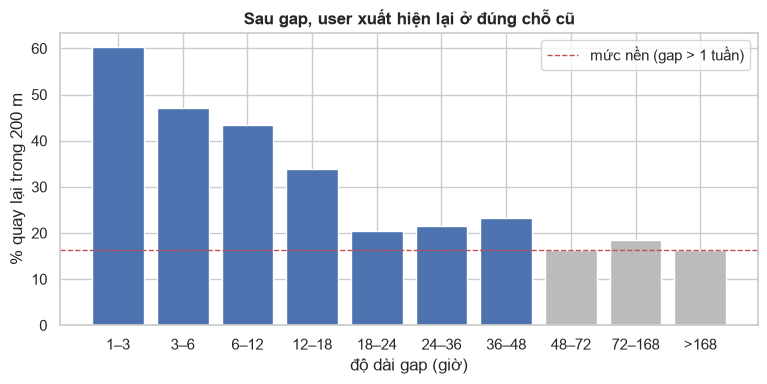

In [5]:
d = np.r_[np.nan, haversine(lat[:-1], lon[:-1], lat[1:], lon[1:])]
gap_h = dtu / 3600
gp = pd.DataFrame({"gap_h": gap_h, "same": d <= 200})[same_user & (gap_h >= 1)]
edges = [1, 3, 6, 12, 18, 24, 36, 48, 72, 168, 1e6]
gr = gp.groupby(pd.cut(gp.gap_h, edges), observed=True).agg(n=("same", "size"), same_place=("same", "mean"))
display(gr.round(3))
print(f"Gap >= 1h: {len(gp):,}; trong đó > 48h: {(gp.gap_h > 48).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 3.8))
lbl = ["1–3", "3–6", "6–12", "12–18", "18–24", "24–36", "36–48", "48–72", "72–168", ">168"]
ax.bar(lbl, gr.same_place * 100, color=["#4c72b0"] * 7 + ["#bbbbbb"] * 3)
ax.axhline(gr.same_place.iloc[-1] * 100, color="#c44e52", ls="--", lw=1, label="mức nền (gap > 1 tuần)")
ax.set(xlabel="độ dài gap (giờ)", ylabel="% quay lại trong 200 m", title="Sau gap, user xuất hiện lại ở đúng chỗ cũ")
ax.legend(); savefig("06_gap_return"); plt.show()

Tỉ lệ quay lại chỉ cho biết gap có **thông tin** hay không, chưa cho biết max_gap ảnh hưởng tới kết quả bao nhiêu.
Kiểm tra trực tiếp: tìm home (place có nhiều giờ đêm nhất) với max_gap = 24, 48, 72 h, rồi so sánh home giữa các phương án.

In [6]:
homes = {}
for g in [24, 48, 72]:
    st = stay_table(detect(200, 20 * 60, max_gap_h=g))
    ps = place_summary(st, window_hours(st))
    h = ps[ps.night_h > 0].sort_values("night_h", ascending=False).groupby("user").head(1).set_index("user")
    homes[g] = h
    if g == 48:
        st48, ps48 = st, ps  # dùng lại cho các mục sau
cmp_gap = []
for g in [24, 72]:
    u = homes[48].index.intersection(homes[g].index)
    dist = haversine(homes[48].loc[u, "lat"], homes[48].loc[u, "lon"], homes[g].loc[u, "lat"], homes[g].loc[u, "lon"])
    cmp_gap.append({"so với max_gap 48h": f"{g}h", "user có home ở cả hai": len(u), "home trùng (≤ 200 m)": f"{(dist <= 200).mean():.1%}",
                    "user có home": len(homes[g])})
print("User có home với max_gap 48h:", len(homes[48]))
pd.DataFrame(cmp_gap)

User có home với max_gap 48h: 168


,so với max_gap 48h,user có home ở cả hai,home trùng (≤ 200 m),user có home
0,24h,165,90.3%,165
1,72h,168,91.7%,169


## 3. Khung đêm và khung hành chính: giờ bắt đầu và kết thúc của các stay dài

Stay qua đêm (>= 6h, bắt đầu 17h–3h): 3595
  bắt đầu p10/p25/p50/p75/p90: [18.13 19.27 21.13 22.73  0.52]
  kết thúc p10/p25/p50/p75/p90: [ 6.05  7.87  9.03 10.92 14.9 ]
Stay ban ngày ngày làm việc (3–12h, bắt đầu 6–11h): 1394
  bắt đầu: [ 7.57  8.12  8.72  9.88 10.81]
  kết thúc: [12.37 14.55 17.62 18.7  19.83]


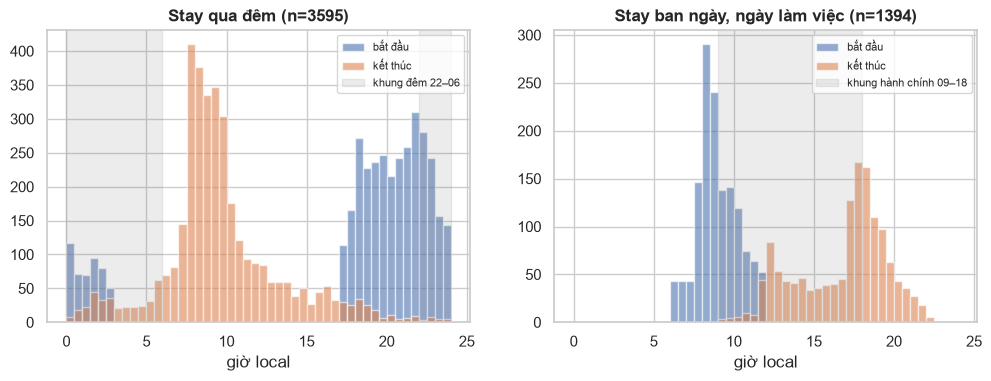

In [7]:
st = st48
work_start = CAL_WORK.reindex(st.start.dt.normalize()).to_numpy()
st["workday"] = np.where(st.in_china & ~pd.isna(work_start), work_start, st.start.dt.day_of_week < 5).astype(bool)
hr = lambda x: x.dt.hour + x.dt.minute / 60
q = [.1, .25, .5, .75, .9]

L = st[st.dur_h >= 6]
night = L[(L.start.dt.hour >= 17) | (L.start.dt.hour < 3)]
ns = (hr(night.start) - 12) % 24 + 12
print(f"Stay qua đêm (>= 6h, bắt đầu 17h–3h): {len(night)}")
print("  bắt đầu p10/p25/p50/p75/p90:", np.round(np.quantile(ns, q) % 24, 2))
print("  kết thúc p10/p25/p50/p75/p90:", np.round(np.quantile(hr(night.end), q), 2))
day = st[st.dur_h.between(3, 12) & st.workday & st.start.dt.hour.between(6, 11)]
print(f"Stay ban ngày ngày làm việc (3–12h, bắt đầu 6–11h): {len(day)}")
print("  bắt đầu:", np.round(np.quantile(hr(day.start), q), 2))
print("  kết thúc:", np.round(np.quantile(hr(day.end), q), 2))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].hist(ns % 24, bins=np.arange(0, 24.5, .5), alpha=.6, label="bắt đầu")
axs[0].hist(hr(night.end), bins=np.arange(0, 24.5, .5), alpha=.6, label="kết thúc")
axs[0].axvspan(22, 24, color="grey", alpha=.15); axs[0].axvspan(0, 6, color="grey", alpha=.15, label="khung đêm 22–06")
axs[0].set(title=f"Stay qua đêm (n={len(night)})", xlabel="giờ local")
axs[1].hist(hr(day.start), bins=np.arange(0, 24.5, .5), alpha=.6, label="bắt đầu")
axs[1].hist(hr(day.end), bins=np.arange(0, 24.5, .5), alpha=.6, label="kết thúc")
axs[1].axvspan(9, 18, color="grey", alpha=.15, label="khung hành chính 09–18")
axs[1].set(title=f"Stay ban ngày, ngày làm việc (n={len(day)})", xlabel="giờ local")
for x in axs: x.legend(fontsize=8)
savefig("06_night_work_windows"); plt.show()

## 4. Cần bao nhiêu đêm / ngày làm việc có dữ liệu?

Đơn vị đo là **số đêm có điểm GPS trong khung 22–06** và **số ngày làm việc có điểm GPS trong khung 09–18** (cùng định nghĩa với NB03 mục 4),
vì đây là con số biết được trước khi chạy stay-point.

Phép thử lấy mẫu con, trên các user có nhiều dữ liệu (≥ 20 đêm, hoặc ≥ 20 ngày làm việc):
- **Đáp án tham chiếu:** home = place có nhiều giờ đêm nhất khi dùng toàn bộ dữ liệu; office = place khác home có nhiều giờ hành chính nhất.
- Lấy ngẫu nhiên k đêm (hoặc k ngày làm việc) có dữ liệu, chỉ dùng giờ stay của các đêm/ngày đó để tìm home (office), lặp 30 lần.
- Đo tỉ lệ kết quả trùng đáp án tham chiếu. Cùng một user nên không bị lẫn với việc user có ít dữ liệu hay nhiều dữ liệu.

Số user dùng cho phép thử: home 49, office 61


,home,office
k,,
1,0.4120,0.2880
2,0.5160,0.3850
3,0.5960,0.4680
5,0.6660,0.5520
7,0.7220,0.5930
10,0.7600,0.6600
15,0.8100,0.7300
20,0.8080,0.7820


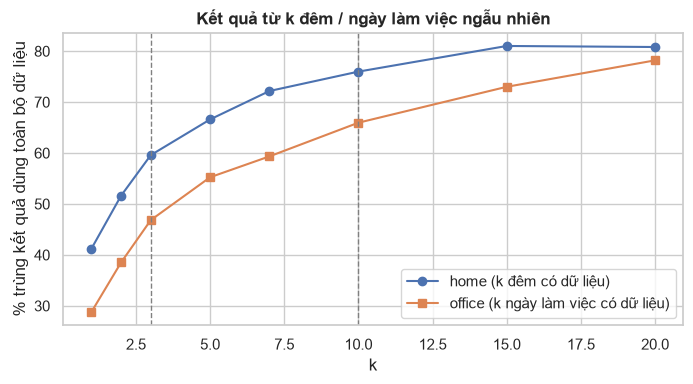

In [8]:
wh = window_hours(st48)
loc = pts.ts_local
hr_l = loc.dt.hour
is_night = ((hr_l >= 22) | (hr_l < 6)).to_numpy()
is_work = (pts.is_workday & hr_l.between(9, 17)).to_numpy()
night_dates = pts[is_night].assign(d=(loc[is_night] - pd.Timedelta(hours=6)).dt.normalize()).groupby("user").d.unique()
work_dates = pts[is_work].assign(d=loc[is_work].dt.normalize()).groupby("user").d.unique()

nh = wh[wh.night].groupby(["user", "night_date", "place"]).hrs.sum()
wk = wh[wh.work].groupby(["user", "date", "place"]).hrs.sum()
home_all = nh.groupby(["user", "place"]).sum().reset_index().sort_values("hrs").groupby("user").tail(1).set_index("user").place
wk_nohome = wk[wk.index.get_level_values("place") != home_all.reindex(wk.index.get_level_values("user")).to_numpy()]
office_all = wk_nohome.groupby(["user", "place"]).sum().reset_index().sort_values("hrs").groupby("user").tail(1).set_index("user").place

rng = np.random.default_rng(0)
K = [1, 2, 3, 5, 7, 10, 15, 20]


def subsample_curve(hours, dates, truth, min_dates=20, reps=30):
    rows = []
    for u in truth.index:
        ds = dates.get(u)
        if ds is None or len(ds) < min_dates:
            continue
        h = hours.loc[u]
        for k in K:
            hit = 0
            for _ in range(reps):
                pick = rng.choice(ds, k, replace=False)
                sub = h[h.index.get_level_values(0).isin(pick)]
                if len(sub):
                    hit += sub.groupby(level=1).sum().idxmax() == truth[u]
            rows.append((u, k, hit / reps))
    return pd.DataFrame(rows, columns=["user", "k", "agree"])


cur_h = subsample_curve(nh, night_dates, home_all)
cur_o = subsample_curve(wk_nohome, work_dates, office_all)
curve = pd.DataFrame({"home": cur_h.groupby("k").agree.mean(), "office": cur_o.groupby("k").agree.mean()})
print(f"Số user dùng cho phép thử: home {cur_h.user.nunique()}, office {cur_o.user.nunique()}")
display(curve.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curve.index, curve.home * 100, "o-", label="home (k đêm có dữ liệu)")
ax.plot(curve.index, curve.office * 100, "s-", label="office (k ngày làm việc có dữ liệu)")
for x in [3, 10]:
    ax.axvline(x, color="grey", ls="--", lw=1)
ax.set(xlabel="k", ylabel="% trùng kết quả dùng toàn bộ dữ liệu", title="Kết quả từ k đêm / ngày làm việc ngẫu nhiên")
ax.legend(); savefig("06_home_stability"); plt.show()

### 4.1 Home có thay đổi theo thời gian không?

Chia thời gian của mỗi user làm hai nửa (theo median thời điểm của các giờ đêm có stay), tìm home của từng nửa rồi so sánh.

In [9]:
nh2 = wh[wh.night].copy()
nh2["half"] = np.where(nh2.h <= nh2.groupby("user").h.transform("median"), "early", "late")
top = (nh2.groupby(["user", "half", "place"]).hrs.sum().reset_index()
       .sort_values("hrs", ascending=False).groupby(["user", "half"]).head(1)
       .pivot(index="user", columns="half", values="place").dropna())
top["agree"] = top.early == top.late
top["nights"] = night_dates.map(len).reindex(top.index).fillna(0)
span = st48.groupby("user").start.agg(lambda x: (x.max() - x.min()).days)
top["span_days"] = span.reindex(top.index)
print(f"User có home ở cả hai nửa: {len(top)}; home hai nửa trùng nhau: {top.agree.mean():.1%}")
print(f"  user có ≥ 10 đêm dữ liệu: {top[top.nights >= 10].agree.mean():.1%} (n={(top.nights >= 10).sum()})")
display(top.groupby(pd.cut(top.span_days, [0, 30, 180, 365, 1e6], labels=["≤ 1 tháng", "1–6 tháng", "6–12 tháng", "> 1 năm"]),
                    observed=True).agree.agg(["size", "mean"]).round(2))

User có home ở cả hai nửa: 162; home hai nửa trùng nhau: 60.5%
  user có ≥ 10 đêm dữ liệu: 63.5% (n=74)


,size,mean
span_days,,
≤ 1 tháng,44,0.5200
1–6 tháng,72,0.6200
6–12 tháng,22,0.6400
> 1 năm,17,0.5300


## 5. Office: có nơi làm việc tách khỏi nhà không, và office ứng viên ít ngày là gì?

Với user có home (mục 2, max_gap 48 h): so sánh giờ hành chính tại home với giờ hành chính tại place khác home có nhiều giờ hành chính nhất
(office ứng viên). Đo thêm số ngày làm việc khác nhau có stay ở office ứng viên và khoảng cách tới home.

User có home và có giờ hành chính: 156
  home giữ > 50% giờ hành chính: 46 user
  không có place nào khác home có giờ hành chính: 7 user


,n_user,km_median,pct_over_50km
office_workdays,,,
0,7,NaN,0.0000
1–2,61,7.9000,19.7000
3–4,26,5.9000,7.7000
5–9,18,8.1000,5.6000
≥10,44,5.1000,4.5000


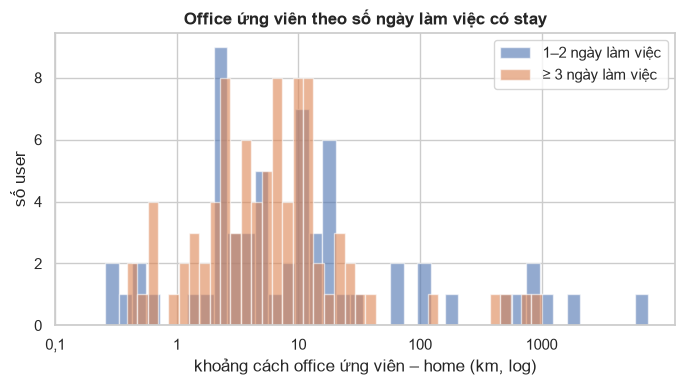

In [10]:
ps = ps48
home = ps.sort_values("night_h", ascending=False).groupby("user").head(1).set_index("user")
home = home[home.night_h > 0]
other = ps.merge(home[["place"]].rename(columns={"place": "home_place"}), left_on="user", right_index=True).query("place != home_place")
office = other[other.work_h > 0].sort_values("work_h", ascending=False).groupby("user").head(1).set_index("user")
tot_work = ps.groupby("user").work_h.sum()
o = pd.DataFrame({"work_h_total": tot_work.reindex(home.index), "home_work_share": home.work_h / tot_work.reindex(home.index),
                  "office_workdays": office.workdays.reindex(home.index).fillna(0),
                  "office_km": haversine(home.lat, home.lon, office.lat.reindex(home.index), office.lon.reindex(home.index)) / 1000})
o = o[o.work_h_total > 0]
print(f"User có home và có giờ hành chính: {len(o)}")
print(f"  home giữ > 50% giờ hành chính: {(o.home_work_share > .5).sum()} user")
print(f"  không có place nào khác home có giờ hành chính: {(o.office_workdays == 0).sum()} user")
b = pd.cut(o.office_workdays, [-.1, 0, 2, 4, 9, 1e6], labels=["0", "1–2", "3–4", "5–9", "≥10"])
tbl = o.groupby(b, observed=True).agg(n_user=("office_km", "size"), km_median=("office_km", "median"),
                                      pct_over_50km=("office_km", lambda x: (x > 50).mean() * 100))
display(tbl.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
for lab_, g in o[o.office_workdays > 0].groupby(o.office_workdays >= 3):
    ax.hist(np.log10(g.office_km.clip(lower=.05)), bins=40, alpha=.6, label="≥ 3 ngày làm việc" if lab_ else "1–2 ngày làm việc")
ax.set_xticks([-1, 0, 1, 2, 3]); ax.set_xticklabels(["0,1", "1", "10", "100", "1000"])
ax.set(xlabel="khoảng cách office ứng viên – home (km, log)", ylabel="số user", title="Office ứng viên theo số ngày làm việc có stay")
ax.legend(); savefig("06_office_support"); plt.show()